# JalanKu — Notebook 01: Dataset

## Tujuan notebook ini
Notebook ini menjelaskan data yang dipakai untuk melatih dan menguji model JalanKu: kelas apa saja yang dideteksi,
dari mana data berasal (video kampus yang direkam sendiri dan lima dataset publik), bagaimana video diolah menjadi
frame yang wajahnya sudah diburamkan, bagaimana label dibuat dan diaudit, serta berapa banyak gambar dan objek di
setiap bagian (train, validasi, test). Notebook ini **hanya membaca** hasil yang sudah tersimpan di `data/` dan
`docs/`; tidak ada pelatihan, evaluasi, atau inferensi model di sini. Semua angka dihitung dari berkas oleh sel kode,
bukan diketik manual, dan setiap bagian ditutup dengan "Bacaan" yang menyebutkan juga kelemahannya.

In [1]:
import csv, json, re, io, html, collections, random
from pathlib import Path

import numpy as np
import yaml
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, HTML, Image as IPImage

# ROOT = akar repo (induk folder notebooks/); dicari ke atas dari folder kerja
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "data"

def rel(p):
    # cetak path relatif terhadap akar repo (tidak pernah path absolut)
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return Path(p).name

def baca(p):
    return Path(p).read_text(encoding="utf-8")

def baca_csv(p):
    with open(p, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

# berkas yang dibutuhkan; data/, runs/, models/ tidak ada di Git
WAJIB = [
    "docs/kelas.md", "docs/dataset-publik.md", "docs/test-set.md", "docs/hasil-audit.md", "docs/rekam-video.md",
    "data/frame-blur", "data/audit-kampus/ringkasan.md", "tools/extract_frames.py",
    "data/dataset-gabung-kotak-v4/data.yaml", "data/dataset-gabung-kotak-v4/sumber.csv",
    "data/dataset-gabung-kotak-v4/labels", "data/dataset-gabung-seg-v4/data.yaml",
    "data/dataset-gabung-seg-v4/sumber.csv", "data/dataset-gabung-seg-v4/labels",
    "data/dataset-test-kotak/labels", "data/dataset-test-kotak/daftar_frame.csv",
    "data/dataset-test-seg/labels",
]
hilang = [w for w in WAJIB if not (ROOT / w).exists()]
if hilang:
    print("BERKAS TIDAK DITEMUKAN (data/, runs/, models/ tidak ikut Git):")
    for w in hilang:
        print("  -", w)
    print("Notebook ini hanya bisa dijalankan ulang di laptop yang memiliki folder tersebut.")
    print("Di tempat lain, lihat saja keluaran yang sudah tersimpan di notebook.")
else:
    print("Semua", len(WAJIB), "berkas sumber ditemukan. ROOT = (akar repo)")

# --- pembantu tampilan ---------------------------------------------------------------------
def tabel(kepala, baris, rata_kanan=None):
    # tampilkan tabel HTML sederhana; kolom di rata_kanan (indeks) rata kanan
    rata_kanan = set(rata_kanan or [])
    h = "<table style='border-collapse:collapse;font-size:90%'>"
    h += "<tr>" + "".join(f"<th style='border:1px solid #888;padding:3px 8px;background:#eee;color:#000'>{c}</th>" for c in kepala) + "</tr>"
    for r in baris:
        h += "<tr>"
        for i, c in enumerate(r):
            al = "right" if i in rata_kanan else "left"
            h += f"<td style='border:1px solid #888;padding:3px 8px;text-align:{al}'>{html.escape(str(c))}</td>"
        h += "</tr>"
    display(HTML(h + "</table>"))

def tabel_md(teks, awal):
    # ambil tabel markdown pertama setelah baris yang memuat `awal` (baris kepala itu sendiri TIDAK ikut); kembalikan list baris
    baris, ada = [], False
    for ln in teks.splitlines():
        if not ada:
            ada = awal in ln
            continue
        s = ln.strip()
        if s.startswith("|"):
            sel = [c.strip() for c in s.strip("|").split("|")]
            if all(set(c) <= set("-: ") for c in sel):
                continue
            baris.append(sel)
        elif baris:
            break
    return baris

def tabel_md_setelah(teks, penanda, kepala):
    # tabel markdown dengan kepala `kepala` yang pertama muncul SETELAH baris `penanda`
    ln = teks.splitlines()
    mulai = next(i for i, x in enumerate(ln) if penanda in x)
    return tabel_md("\n".join(ln[mulai:]), kepala)

def angka_md(s):
    s = s.replace("**", "").strip()
    return 0 if s in ("-", "") else int(s)

# --- lacak gambar yang ditampilkan + daftar putih privasi -----------------------------------
GAMBAR_TAMPIL = []
PUTIH = ("data/frame-blur/", "data/dataset-")   # + data/dataset-*/images/
def cek_putih(p):
    r = rel(p)
    ok = r.startswith("data/frame-blur/") or (r.startswith("data/dataset-") and "/images/" in r)
    assert ok, f"gambar di luar daftar putih privasi: {r}"
    assert "rumah" not in r.lower(), r
    GAMBAR_TAMPIL.append(r)

def tampil_jpeg(gambar_pil, mutu=80):
    buf = io.BytesIO()
    gambar_pil.convert("RGB").save(buf, "JPEG", quality=mutu)
    display(IPImage(data=buf.getvalue(), format="jpeg"))

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("Siap.")

Semua 17 berkas sumber ditemukan. ROOT = (akar repo)
Siap.


## 1. Kelas yang dideteksi
JalanKu memakai **dua model**: model kotak (*object detection*) untuk benda di jalur, dan model segmentasi untuk permukaan
jalan (jumlah kelas keduanya dicetak oleh sel di bawah). Kelas **tangga** ada di dua model: kotak untuk peringatan, mask untuk bentuk.
Daftar kelas dan definisinya di bawah dibaca dari `docs/kelas.md` (v1.8) dan dari `data.yaml` kedua dataset.

In [2]:
kelas_md = baca(ROOT / "docs/kelas.md")
tab_kelas = tabel_md(kelas_md, "| ID | Kelas | Yang dilabel |")
defin = {r[1]: r[2] for r in tab_kelas}                                          # nama -> definisi

yk = yaml.safe_load(baca(DATA / "dataset-gabung-kotak-v4/data.yaml"))
ys = yaml.safe_load(baca(DATA / "dataset-gabung-seg-v4/data.yaml"))
NAMA_KOTAK = [yk["names"][i] for i in range(len(yk["names"]))]
NAMA_SEG = [ys["names"][i] for i in range(len(ys["names"]))]
print("Kelas kotak :", len(NAMA_KOTAK), NAMA_KOTAK)
print("Kelas seg   :", len(NAMA_SEG), NAMA_SEG)

def ringkas(s, n=150):
    s = s.replace("`", "")
    return s if len(s) <= n else s[:n].rsplit(" ", 1)[0] + " ..."

baris = []
for i, n in enumerate(NAMA_KOTAK):
    baris.append(["Kotak", i, n, ringkas(defin.get(n, ""))])
for i, n in enumerate(NAMA_SEG):
    baris.append(["Segmentasi", i, n, ringkas(defin.get(n, ""))])
tabel(["Model", "ID model", "Kelas", "Definisi singkat (dari kelas.md)"], baris)

# tiga aturan pembeda yang paling sering membingungkan, dikutip dari kelas.md
for kunci in ("**pohon:**", "**tepian:**", "**tangga:**"):
    ln = next(x for x in kelas_md.splitlines() if x.startswith("- " + kunci))
    print(ringkas(ln[2:], 330)); print()

Kelas kotak : 8 ['pilar', 'pohon', 'tepian', 'orang', 'tanaman_pot', 'kursi', 'kendaraan', 'tangga']
Kelas seg   : 3 ['jalur_jalan', 'jalan_kendaraan', 'tangga']


Model,ID model,Kelas,Definisi singkat (dari kelas.md)
Kotak,0,pilar,"Tiang gedung, tiang lampu jalan, tiang rambu, bollard, kerucut lalu lintas, totem/papan nama besar yang berdiri bebas. Bukan sirip, kosen, atau ..."
Kotak,1,pohon,Hanya batang pohon yang tumbuh dari tanah
Kotak,2,tepian,"Tepi trotoar, undakan tunggal, perbedaan tinggi lantai (bukan tangga)"
Kotak,3,orang,"Berdiri, berjalan, atau duduk (satu kelas)"
Kotak,4,tanaman_pot,"Pot dan tanamannya (satu objek), bedeng/planter berisi tanaman, semak di pinggir jalur"
Kotak,5,kursi,"Kursi dan bangku, termasuk bangku taman"
Kotak,6,kendaraan,"Motor, mobil, sepeda, truk, dan bus, terparkir maupun bergerak"
Kotak,7,tangga,Tangga naik atau turun dengan dua anak tangga atau lebih
Segmentasi,0,jalur_jalan,"Permukaan untuk pejalan kaki, termasuk dalam gedung"
Segmentasi,1,jalan_kendaraan,Jalan yang dipakai motor dan mobil


**pohon:** batang saja dari pangkal ke atas sejauh terlihat, daun dan tajuk tidak ikut. Kalau batang sebagian tertutup daun, label bagian batang yang terlihat saja. Pohon dalam pot masuk tanaman_pot.

**tepian:** satu undakan atau tepi yang tingginya berubah (tepi trotoar, satu anak tangga di pintu masuk). Dua anak tangga atau lebih masuk tangga. Pinggiran taman atau planter: kerb rendah setinggi sekitar satu anak tangga = tepian; dinding planter yang lebih tinggi dari itu bukan tepian, cukup lewat batas jalur_jalan. Teras ...

**tangga:** satu kotak atau mask untuk seluruh bagian tangga yang terlihat, naik maupun turun. Pegangan tangga ikut di dalamnya, tidak dilabel terpisah. Tangga dengan bordes: anak tangga = tangga, bordes datar = jalur_jalan terpisah (v1.8). Eskalator tidak dilabel (sementara), termasuk pelat landasannya.



**Bacaan.** Pembedaan yang paling halus ada pada tiga kelas: *pohon* hanya batangnya (daun dan tajuk tidak dilabel),
*tepian* adalah satu undakan atau tepi trotoar, dan *tangga* baru dipakai bila ada dua anak tangga atau lebih.
Pembedaan ini menentukan kelas mana yang tampak "salah" saat evaluasi: model yang melihat satu anak tangga lalu
menyebutnya tangga akan dihitung keliru walaupun alasannya masuk akal. ID di model segmentasi (0–2) berbeda dari ID
di `kelas.md` (7–9) karena dua model memakai daftar kelas sendiri-sendiri.

## 2. Sumber data
Data latih berasal dari dua sumber: **video kampus** yang direkam tim (UBM Tower, Alfa Tower, area luar) dan
**dataset publik** yang dipetakan ke kelas JalanKu. Tabel atribusi dibaca dari `docs/dataset-publik.md`; jumlah
gambar dan kotak yang benar-benar masuk ke dataset gabung v4 dihitung dari `sumber.csv` dan `kotak_akhir.csv`.

In [3]:
dp = baca(ROOT / "docs/dataset-publik.md")
atribusi = tabel_md(dp, "| No | Dataset |")
# ringkasan pemetaan (diringkas dari bagian "Pemetaan kelas" di dataset-publik.md) dan jenis label
def ringkas_l(s, n=60):
    s = s.replace("`", "")
    return s if len(s) <= n else s[:n].rsplit(" ", 1)[0] + " ..."
RINGKAS = {
    "ROD-Dataset": ("Kotak", "Bike/Car/Motorcycle/Truck/Bus -> kendaraan; Person -> orang; Stairs -> tangga; Electrical Pole -> pilar; Bench/Chair -> kursi; Plant Pot -> tanaman_pot. Gambar ber-Tree dibuang."),
    "OOD": ("Kotak", "curb -> tepian; pole/street_light/roadblock -> pilar; kendaraan, person, bench, stairs dipetakan; gambar ber-tree dibuang."),
    "Unstructured Road Obstacle Detection": ("Kotak", "tree -> pohon (batang); vehicle/two-wheeler -> kendaraan; pole -> pilar; stairs -> tangga."),
    "Dataset Lingkungan Trotoar Ver2 (Indonesia)": ("Kotak", "Dipetakan lewat ID: motor/mobil -> kendaraan, orang, batang pohon, kolom/bollard/tiang -> pilar, pot, kursi."),
    "Sidewalk Segment": ("Mask (guiding block)", "TIDAK DIPAKAI: mask hanya jalur guiding block, bentrok dengan definisi jalur_jalan."),
}
sumber_csv = baca_csv(DATA / "dataset-gabung-kotak-v4/sumber.csv")
n_img_pub = collections.Counter(r["sumber"] for r in sumber_csv if r["sumber"] != "campus")
KUNCI = {"ROD-Dataset": "rod", "OOD": "ood", "Unstructured Road Obstacle Detection": "unstructured",
         "Dataset Lingkungan Trotoar Ver2 (Indonesia)": "trotoar", "Sidewalk Segment": None}
baris = []
for r in atribusi:
    nama = r[1]
    jenis, peta = RINGKAS.get(nama, ("?", ""))
    k = KUNCI.get(nama)
    pakai = n_img_pub[k] if k else 0
    baris.append([nama, r[2].replace("`", ""), jenis, peta, ringkas_l(r[4]), pakai])
tabel(["Dataset", "Pembuat", "Jenis label", "Pemetaan kelas (ringkas)", "Lisensi", "Gambar di train v4"], baris, rata_kanan=[5])
print("Total gambar publik di train v4:", sum(n_img_pub.values()))

# kotak publik: asli vs hasil isi-label COCO (pseudo-label), dari kolom n_asli / n_coco di sumber.csv
ac = collections.defaultdict(lambda: [0, 0])
for r in sumber_csv:
    if r["sumber"] != "campus":
        ac[r["sumber"]][0] += int(r["n_asli"]); ac[r["sumber"]][1] += int(r["n_coco"])
baris = [[k, a, c, f"{100*c/(a+c):.0f}%"] for k, (a, c) in sorted(ac.items())]
tot_a = sum(a for a, c in ac.values()); tot_c = sum(c for a, c in ac.values())
baris.append(["total", tot_a, tot_c, f"{100*tot_c/(tot_a+tot_c):.0f}%"])
tabel(["Dataset publik", "Kotak label asli", "Kotak isi-COCO (pseudo-label)", "Porsi pseudo-label"], baris, rata_kanan=[1, 2, 3])

Dataset,Pembuat,Jenis label,Pemetaan kelas (ringkas),Lisensi,Gambar di train v4
ROD-Dataset,Abtin Zandi (Kaggle abtinzandi),Kotak,Bike/Car/Motorcycle/Truck/Bus -> kendaraan; Person -> orang; Stairs -> tangga; Electrical Pole -> pilar; Bench/Chair -> kursi; Plant Pot -> tanaman_pot. Gambar ber-Tree dibuang.,MIT (sebagian gambar berasal dari Roboflow Universe dan ...,400
OOD,workspace Roboflow fpn,Kotak,"curb -> tepian; pole/street_light/roadblock -> pilar; kendaraan, person, bench, stairs dipetakan; gambar ber-tree dibuang.",CC BY 4.0,600
Unstructured Road Obstacle Detection,workspace Roboflow mtechcv,Kotak,tree -> pohon (batang); vehicle/two-wheeler -> kendaraan; pole -> pilar; stairs -> tangga.,CC BY 4.0,600
Dataset Lingkungan Trotoar Ver2 (Indonesia),"workspace Roboflow dataset-lingkungan-trotoar-ver2, proyek dataset-labelled; diunduh dari fork jeka-workspace/dataset-labelled-sqkiz",Kotak,"Dipetakan lewat ID: motor/mobil -> kendaraan, orang, batang pohon, kolom/bollard/tiang -> pilar, pot, kursi.",CC BY 4.0,700
Sidewalk Segment,pengguna Kaggle lemnix,Mask (guiding block),"TIDAK DIPAKAI: mask hanya jalur guiding block, bentrok dengan definisi jalur_jalan.",CC BY-SA 4.0 (turunan yang dipublikasikan wajib berlisensi ...,0


Total gambar publik di train v4: 2300


Dataset publik,Kotak label asli,Kotak isi-COCO (pseudo-label),Porsi pseudo-label
ood,1488,710,32%
rod,513,238,32%
trotoar,7174,355,5%
unstructured,654,370,36%
total,9829,1673,15%


**Bacaan.** Dataset publik memberi variasi objek (kendaraan, kursi, pilar, tangga) yang tidak cukup terekam di
kampus, tetapi definisi label mereka tidak persis sama dengan `kelas.md`, dan sebagian kotaknya adalah
*pseudo-label* dari model COCO (kolom terakhir), bukan label manusia. Dataset publik hanya dipakai untuk model kotak;
model segmentasi dilatih dari data kampus saja. Dataset *Sidewalk Segment* diunduh tetapi tidak dipakai.

## 3. Perekaman kampus
Video direkam dengan HP portrait (spesifikasi di sel berikut, dibaca dari `docs/rekam-video.md`) pada dua sudut pandang
(POV): **dada** (HP setinggi dada, sudut pandang utama pemakaian nyata) dan **mata** (sejajar mata). Nama folder di `data/frame-blur/` mengikuti pola
`lokasi_tanggal_sesi_pov`. Bagian ini membaca nama folder, jumlah frame per folder, lalu mengelompokkannya per lokasi
beserta pembagian **train / val / test**.

**Pembagian per lokasi, bukan per frame.** Frame yang berdekatan dalam satu video hampir identik. Jika dibagi acak per
frame, frame yang mirip akan jatuh di train dan val sekaligus, sehingga skor val tampak bagus padahal model hanya
mengenali ulang tempat yang sama (*kebocoran*). Karena itu seluruh lokasi dipisah: sebagian lokasi untuk train, sebagian untuk
val, dan lokasi yang tidak pernah dilihat saat latihan untuk test (jumlah lokasi per split dicetak di bawah tabel).

In [4]:
rv = baca(ROOT / "docs/rekam-video.md")
sek = rv.split("## Aturan rekam")[1].split("##")[0]
print("Aturan rekam (docs/rekam-video.md):")
for ln in sek.strip().splitlines():
    print("  ", ln)
print("Catatan: dokumen itu adalah rencana per awal rekaman. Pembagian split dan POV yang dipakai di bawah dibaca dari data;")
print("         misalnya lokasi test akhirnya memakai POV dada dan mata (lihat docs/test-set.md), tidak hanya dada seperti rencana awal.")

Aturan rekam (docs/rekam-video.md):
   - POV utama setinggi dada (untuk training dan test). POV sejajar mata hanya tambahan untuk training, tidak dipakai di test.
   - HP posisi portrait (vertikal), sama di semua video. Kamera 1x, jangan zoom atau wide.
   - Jalan pelan, berhenti sebentar di depan rintangan.
   - Resolusi 1080p, 30 fps.
   - Durasi per video 30 detik sampai 5 menit. Sebisa mungkin satu lokasi per video.
   - Variasi: siang terang, sore, area ramai dan sepi.
   - Hindari close-up wajah. Tetap akan diblur otomatis sebelum dipakai.
Catatan: dokumen itu adalah rencana per awal rekaman. Pembagian split dan POV yang dipakai di bawah dibaca dari data;
         misalnya lokasi test akhirnya memakai POV dada dan mata (lihat docs/test-set.md), tidak hanya dada seperti rencana awal.


47 folder video (dada/mata terpisah), 18 lokasi, 4150 frame (wajah sudah diburamkan) di data/frame-blur/


Lokasi,Split,Video,POV,Tanggal rekam,Frame diekstrak,Frame berlabel (unik),Berlabel / diekstrak
alfamart-lt2,train,2,dada+mata,2026-10-30,81,19,23.5%
halaman-ubm,train,2,dada+mata,2026-11-07,196,40,20.4%
jalanan-ubm,train,2,dada+mata,2026-11-07,246,43,17.5%
lab-iota1-lt9-ubm-tower,train,4,dada+mata,2026-10-30,140,31,22.1%
lab1-lt5-alfa-tower,train,4,dada+mata,2026-10-30,91,18,19.8%
lorong-lt3-eskalator-alfa-tower,train,2,dada+mata,2026-10-30,432,37,8.6%
lorong-lt5-alfa-tower,train,2,dada+mata,2026-10-30,197,29,14.7%
lorong-lt9-ubm-tower,train,6,dada+mata,2026-10-30,279,27,9.7%
parkiran-motor-b1-ubm-tower,train,3,dada+mata,2026-10-30,700,54,7.7%
samping-ubm,train,2,dada+mata,2026-11-07,396,67,16.9%


Jumlah lokasi per split: {'train': 12, 'val': 3, 'test': 3}


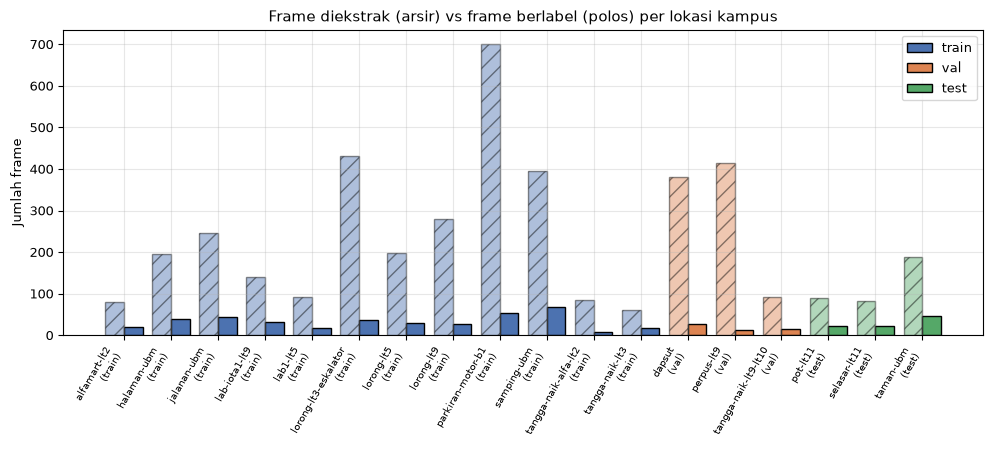

Frame non-test: 3790 | frame lokasi test: 360
Berlabel unik: train 391 + val 54 = 445 (non-test); test: 91


In [5]:
# --- semua folder frame, dikelompokkan per lokasi -----------------------------------------------
def urai(nama):
    lok, tgl, sesi, pov = nama.rsplit("_", 3)
    return lok, tgl, sesi, pov

folder = sorted(d for d in (DATA / "frame-blur").iterdir() if d.is_dir())
per_lok = collections.defaultdict(lambda: {"frame": 0, "pov": set(), "video": 0, "tgl": set()})
for d in folder:
    lok, tgl, sesi, pov = urai(d.name)
    n = len(list(d.glob("*.jpg")))
    e = per_lok[lok]; e["frame"] += n; e["pov"].add(pov); e["video"] += 1; e["tgl"].add(tgl)
print(f"{len(folder)} folder video (dada/mata terpisah), {len(per_lok)} lokasi, "
      f"{sum(e['frame'] for e in per_lok.values())} frame (wajah sudah diburamkan) di data/frame-blur/")

# --- pembagian: dari sumber.csv (train/val) dan daftar test ---------------------------------------
uniq = [r for r in sumber_csv if r["sumber"] == "campus" and r["ulang"] == "0"]
split_lok, berlabel = {}, collections.Counter()
for r in uniq:
    lok = r["image"].split("_")[0]
    split_lok[lok] = r["split"]; berlabel[lok] += 1
test_daftar = baca_csv(DATA / "dataset-test-kotak/daftar_frame.csv")
for r in test_daftar:
    split_lok[r["lokasi"]] = "test"; berlabel[r["lokasi"]] += 1
assert set(split_lok) == set(per_lok), set(per_lok) ^ set(split_lok)

URUT = {"train": 0, "val": 1, "test": 2}
baris = []
for lok in sorted(per_lok, key=lambda l: (URUT[split_lok[l]], l)):
    e = per_lok[lok]
    baris.append([lok, split_lok[lok], e["video"], "+".join(sorted(e["pov"])), ", ".join(sorted(e["tgl"])),
                  e["frame"], berlabel[lok], f"{100*berlabel[lok]/e['frame']:.1f}%"])
tabel(["Lokasi", "Split", "Video", "POV", "Tanggal rekam", "Frame diekstrak", "Frame berlabel (unik)", "Berlabel / diekstrak"],
      baris, rata_kanan=[2, 5, 6, 7])

# --- diagram batang: frame diekstrak vs frame berlabel per lokasi ---------------------------------
lok_urut = [b[0] for b in baris]
fr = [per_lok[l]["frame"] for l in lok_urut]; bl = [berlabel[l] for l in lok_urut]
print("Jumlah lokasi per split:", dict(collections.Counter(split_lok.values())))
warna = {"train": "#4c72b0", "val": "#dd8452", "test": "#55a868"}
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(lok_urut)); w = 0.4
ax.bar(x - w/2, fr, w, color=[warna[split_lok[l]] for l in lok_urut], alpha=0.45, edgecolor="k", hatch="//")
ax.bar(x + w/2, bl, w, color=[warna[split_lok[l]] for l in lok_urut], edgecolor="k")
ax.set_xticks(x); ax.set_xticklabels([l.replace("-ubm-tower", "").replace("-alfa-tower", "") + f"\n({split_lok[l]})" for l in lok_urut], rotation=60, ha="right", fontsize=7)
ax.set_ylabel("Jumlah frame"); ax.set_title("Frame diekstrak (arsir) vs frame berlabel (polos) per lokasi kampus")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(fc=warna[s], ec="k", label=s) for s in ("train", "val", "test")], loc="upper right")
fig.tight_layout(); plt.show()

# --- total ----------------------------------------------------------------------------------------
TOT_NONTEST = sum(per_lok[l]["frame"] for l in per_lok if split_lok[l] != "test")
TOT_TEST_FR = sum(per_lok[l]["frame"] for l in per_lok if split_lok[l] == "test")
N_LAB_TRAIN = sum(1 for r in uniq if r["split"] == "train")
N_LAB_VAL = sum(1 for r in uniq if r["split"] == "val")
print(f"Frame non-test: {TOT_NONTEST} | frame lokasi test: {TOT_TEST_FR}")
print(f"Berlabel unik: train {N_LAB_TRAIN} + val {N_LAB_VAL} = {N_LAB_TRAIN+N_LAB_VAL} (non-test); test: {len(test_daftar)}")

**Bacaan.** Hanya sebagian kecil frame yang pernah diberi label manual (kolom terakhir); label manual mahal, jadi
frame dipilih bertahap dan bukan seluruhnya. Lokasi **dapsut** (area parkir dan luar gedung) berada di val dan menyumbang
frame val terbanyak (kolom "Frame berlabel"), sehingga skor val sangat dipengaruhi segelintir lokasi. Lokasi test sengaja tidak
tumpang tindih dengan train/val, tetapi ada catatan kebocoran visual: area test **taman-ubm** ternyata ikut terekam di video lokasi
latih lain. Sebanyak **16 frame** dikeluarkan: **12 frame latih lama** (baseline dilatih dengan 12 frame ini; setelah kampus di-*oversample* x4 menjadi
48 dari 3.080 gambar latih model kotak) ditambah **4 frame kandidat ronde 2** yang dibuang saat review sebelum sempat dilabel (sumber: `docs/test-set.md`,
`docs/hasil-ronde2.md`; rincian di bagian Keterbatasan).

## 4. Pra-pemrosesan
Alur dari video sampai dataset siap latih:

1. **Ekstraksi frame** (`tools/extract_frames.py`): sampling per detik (nilai pastinya di tabel pengaturan), frame mirip dibuang.
2. **Pemburaman kepala orang** dilakukan di memori sebelum frame ditulis ke disk. Frame yang belum diburamkan tidak
   pernah disimpan, karena repo ini publik.
3. **Label draf otomatis** (`tools/autolabel_v2.py`): kombinasi SegFormer ADE20K, YOLO11x-seg COCO, Grounding DINO,
   dan SAM 2.1 menghasilkan polygon draf. Untuk ronde 2 dan ronde 4, sumber draf juga dipilih berdasarkan studi di
   val (tercatat di log ronde), bukan hanya satu pipeline.
4. **Tinjauan manual penuh** di X-AnyLabeling oleh anggota tim; draf hanya menghemat waktu, label akhir adalah hasil
   koreksi manusia.
5. **Audit label** terhadap aturan R1–R7 (bagian 7).
6. **Penyusunan dataset gabung**: frame kampus di-*oversample* di train (kolom `ulang` di `sumber.csv`; faktornya dihitung di bawah), digabung dengan gambar publik terpilih.

In [6]:
src = baca(ROOT / "tools/extract_frames.py")
# konstanta modul
konst = dict(re.findall(r"^([A-Z_]+)\s*=\s*([0-9.]+)", src, flags=re.M))
# default argumen CLI
defaults = {}
for ln in src.splitlines():
    m = re.search(r'add_argument\("--([\w-]+)".*?default=("?[\w.]+"?)', ln)
    if m:
        defaults[m.group(1)] = m.group(2).strip('"')
baris = [
    ["Frame per detik (--fps)", defaults.get("fps"), "sampling berdasarkan timestamp asli frame"],
    ["Ambang duplikat (--dedup-threshold)", defaults.get("dedup-threshold"), "selisih rata-rata piksel 0-255; di bawah ini dibuang"],
    ["Model deteksi orang", defaults.get("model"), "hanya untuk mencari kepala yang diburamkan"],
    ["Confidence minimum orang", defaults.get("conf"), ""],
    ["Kepala = bagian atas kotak orang", konst.get("HEAD_RATIO"), "40% bagian atas"],
    ["Pelebaran kotak kepala", konst.get("HEAD_PAD"), "10% di kiri dan kanan"],
    ["Ukuran piksel blur (PIXEL_SIZE)", konst.get("PIXEL_SIZE"), "sisi terpanjang kepala diperkecil ke ~8 px (pixelate)"],
    ["Kualitas JPG", konst.get("JPG_QUALITY"), ""],
]
tabel(["Pengaturan ekstraksi", "Nilai", "Keterangan"], baris)

# statistik dari _manifest.csv tiap folder
n_frame = n_buram = n_dgn_orang = n_manifest = 0
selang = []
folder_selisih = {}
for d in folder:
    mf = d / "_manifest.csv"
    if not mf.exists():
        continue
    ada = {p.name for p in d.glob("*.jpg")}
    rows_all = baca_csv(mf)
    n_manifest += len(rows_all)
    if len(rows_all) != len(ada):
        folder_selisih[d.name] = (len(rows_all), len(ada))
    rows = [r for r in rows_all if r["filename"] in ada]        # hanya frame yang masih ada di disk
    ts = [float(r["timestamp_s"]) for r in rows]
    selang += list(np.diff(ts))
    for r in rows:
        n_frame += 1
        p = int(r["persons_blurred"]); n_buram += p; n_dgn_orang += (p > 0)
print(f"Dari {n_frame} frame yang ada di disk: {n_dgn_orang} frame ({100*n_dgn_orang/n_frame:.1f}%) memuat orang yang kepalanya diburamkan, "
      f"total {n_buram} kepala diburamkan.")
print(f"Manifest mencatat {n_manifest} frame, file di disk {n_frame}: selisih {n_manifest - n_frame}.")
for k, (a, b) in folder_selisih.items():
    print(f"  folder {k}: manifest {a}, file {b}")
print("  (kemungkinan frame yang dibuang manual setelah ekstraksi, mis. yang memperlihatkan area taman test; lihat docs/rekam-video.md)")
print(f"Selang waktu antar frame tersimpan: median {np.median(selang):.2f} detik, p90 {np.percentile(selang, 90):.2f} detik.")

Pengaturan ekstraksi,Nilai,Keterangan
Frame per detik (--fps),1.0,sampling berdasarkan timestamp asli frame
Ambang duplikat (--dedup-threshold),4.0,selisih rata-rata piksel 0-255; di bawah ini dibuang
Model deteksi orang,yolo11n.pt,hanya untuk mencari kepala yang diburamkan
Confidence minimum orang,0.25,
Kepala = bagian atas kotak orang,0.40,40% bagian atas
Pelebaran kotak kepala,0.10,10% di kiri dan kanan
Ukuran piksel blur (PIXEL_SIZE),8,sisi terpanjang kepala diperkecil ke ~8 px (pixelate)
Kualitas JPG,95,


Dari 4150 frame yang ada di disk: 1328 frame (32.0%) memuat orang yang kepalanya diburamkan, total 2654 kepala diburamkan.
Manifest mencatat 4162 frame, file di disk 4150: selisih 12.
  folder tangga-naik-alfa-lt2_2026-10-30_01_dada: manifest 48, file 45
  folder tangga-naik-alfa-lt2_2026-10-30_01_mata: manifest 50, file 41
  (kemungkinan frame yang dibuang manual setelah ekstraksi, mis. yang memperlihatkan area taman test; lihat docs/rekam-video.md)
Selang waktu antar frame tersimpan: median 1.00 detik, p90 1.00 detik.


In [7]:
# --- asal frame berlabel: pilot / ronde 2 / ronde 4 (dari daftar pilihan tiap ronde) --------------
def stems(p):
    return {r["stem"] for r in baca_csv(p)} if p.exists() else set()
s_r2 = stems(DATA / "ronde2/pilihan.csv"); s_r4 = stems(DATA / "ronde4/pilihan.csv")
asal = collections.Counter()
for r in uniq:
    st = Path(r["image"]).stem
    a = "ronde 4" if st in s_r4 else "ronde 2" if st in s_r2 else "pilot"
    asal[(r["split"], a)] += 1
baris = [[a, asal[("train", a)], asal[("val", a)]] for a in ("pilot", "ronde 2", "ronde 4")]
baris.append(["total", sum(asal[("train", a)] for a in ("pilot", "ronde 2", "ronde 4")), sum(asal[("val", a)] for a in ("pilot", "ronde 2", "ronde 4"))])
tabel(["Asal frame berlabel", "Train (unik)", "Val"], baris, rata_kanan=[1, 2])

# --- oversampling x4: jumlah unik vs dengan pengulangan --------------------------------------------
camp = [r for r in sumber_csv if r["sumber"] == "campus"]
ulang_cnt = collections.Counter((r["split"], r["ulang"]) for r in camp)
print("Distribusi kolom `ulang` pada sumber.csv (kampus):", dict(sorted(ulang_cnt.items())))
FAK = max(int(u) for (s, u) in ulang_cnt if s == "train") + 1
print("Faktor pengulangan frame kampus di train =", FAK)
tr_unik = ulang_cnt[("train", "0")]; tr_total = sum(v for (s, u), v in ulang_cnt.items() if s == "train")
n_pub = sum(1 for r in sumber_csv if r["sumber"] != "campus")
tabel(["Bagian train kotak v4", "Gambar unik", "Gambar dengan pengulangan (yang dibaca trainer)"],
      [["Kampus", tr_unik, tr_total], ["Publik", n_pub, n_pub], ["Total", tr_unik + n_pub, tr_total + n_pub]], rata_kanan=[1, 2])
print(f"Porsi kampus dalam train: {100*tr_unik/(tr_unik+n_pub):.1f}% (unik) vs {100*tr_total/(tr_total+n_pub):.1f}% (setelah pengulangan)")

Asal frame berlabel,Train (unik),Val
pilot,183,54
ronde 2,66,0
ronde 4,142,0
total,391,54


Distribusi kolom `ulang` pada sumber.csv (kampus): {('train', '0'): 391, ('train', '1'): 391, ('train', '2'): 391, ('train', '3'): 391, ('val', '0'): 54}
Faktor pengulangan frame kampus di train = 4


Bagian train kotak v4,Gambar unik,Gambar dengan pengulangan (yang dibaca trainer)
Kampus,391,1564
Publik,2300,2300
Total,2691,3864


Porsi kampus dalam train: 14.5% (unik) vs 40.5% (setelah pengulangan)


**Bacaan.** Pemburaman memakai deteksi orang, jadi kepala yang tidak terdeteksi (terpotong, kecil, membelakangi
kamera) berisiko tidak ikut diburamkan; karena itu gambar yang ditampilkan di notebook ini dibatasi ke folder yang
sudah diperiksa dan tetap diperiksa mata sebelum dipublikasikan. Pengulangan membuat data kampus (yang paling mirip
kondisi pemakaian) berbobot lebih besar di trainer, tetapi **tidak menambah informasi baru**: satu frame yang sama dilihat
beberapa kali (dengan augmentasi berbeda saat training), sehingga risiko *overfitting* ke frame kampus lebih tinggi daripada
yang ditunjukkan jumlah gambar.

## 5. Jumlah gambar dan instance
Semua angka berikut dihitung dengan membaca file label YOLO satu per satu (`labels/*.txt`, satu baris = satu objek)
dan memetakannya ke baris di `sumber.csv`.

In [8]:
def hitung_label(dir_label, nkelas, peta_sumber=None):
    # kembalikan {kunci: Counter kelas -> jumlah}; kunci = (split, sumber, ulang>0?) bila peta_sumber ada
    hasil = collections.defaultdict(collections.Counter)
    for f in sorted(Path(dir_label).glob("*.txt")):
        kunci = peta_sumber[f.stem] if peta_sumber else "all"
        for ln in f.read_text().splitlines():
            if ln.strip():
                hasil[kunci][int(ln.split()[0])] += 1
    return hasil

# --- jumlah gambar per split per sumber -----------------------------------------------------------
img_cnt = collections.Counter((r["split"], r["sumber"]) for r in sumber_csv)
SUMBERS = ["campus", "trotoar", "unstructured", "ood", "rod"]
baris = []
for s in SUMBERS:
    tu = tr_unik if s == "campus" else img_cnt[("train", s)]
    baris.append([s, tu, img_cnt[("train", s)], img_cnt[("val", s)]])
baris.append(["total", tr_unik + n_pub, sum(img_cnt[("train", s)] for s in SUMBERS), sum(img_cnt[("val", s)] for s in SUMBERS)])
tabel(["Sumber (kotak v4)", "Train unik", f"Train (kampus x{FAK})", "Val"], baris, rata_kanan=[1, 2, 3])
print("Segmentasi v4 (kampus saja):", dict(collections.Counter(r["split"] for r in baca_csv(DATA / "dataset-gabung-seg-v4/sumber.csv"))))

# --- instance kotak per kelas ---------------------------------------------------------------------
peta = {}
for r in sumber_csv:
    st = Path(r["image"]).stem
    if r["sumber"] == "campus":
        peta[st] = (r["split"], "kampus-unik" if r["ulang"] == "0" else "kampus-ulang")
    else:
        peta[st] = (r["split"], "publik")
kotak = {}
for sp in ("train", "val"):
    kotak.update({k: v for k, v in hitung_label(DATA / f"dataset-gabung-kotak-v4/labels/{sp}", 8, peta).items()})
def vec(kunci):
    c = kotak.get(kunci, collections.Counter()); return [c[i] for i in range(8)]
v_ku, v_kr, v_pub, v_val = vec(("train", "kampus-unik")), vec(("train", "kampus-ulang")), vec(("train", "publik")), vec(("val", "kampus-unik"))
v_k4 = [a + b for a, b in zip(v_ku, v_kr)]                  # kampus unik + salinan = efektif x4
v_train = [a + b for a, b in zip(v_k4, v_pub)]
baris = [[NAMA_KOTAK[i], v_ku[i], v_k4[i], v_pub[i], v_train[i], v_val[i]] for i in range(8)]
baris.append(["total", sum(v_ku), sum(v_k4), sum(v_pub), sum(v_train), sum(v_val)])
tabel(["Kelas (kotak)", "Kampus train (unik)", f"Kampus train (dgn x{FAK})", "Publik train", "Train efektif", "Val"], baris, rata_kanan=[1, 2, 3, 4, 5])

Sumber (kotak v4),Train unik,Train (kampus x4),Val
campus,391,1564,54
trotoar,700,700,0
unstructured,600,600,0
ood,600,600,0
rod,400,400,0
total,2691,3864,54


Segmentasi v4 (kampus saja): {'train': 391, 'val': 54}


Kelas (kotak),Kampus train (unik),Kampus train (dgn x4),Publik train,Train efektif,Val
pilar,272,1088,2672,3760,34
pohon,150,600,1400,2000,10
tepian,331,1324,328,1652,45
orang,138,552,1766,2318,29
tanaman_pot,85,340,581,921,10
kursi,197,788,1200,1988,22
kendaraan,440,1760,2806,4566,108
tangga,36,144,749,893,5
total,1649,6596,11502,18098,263


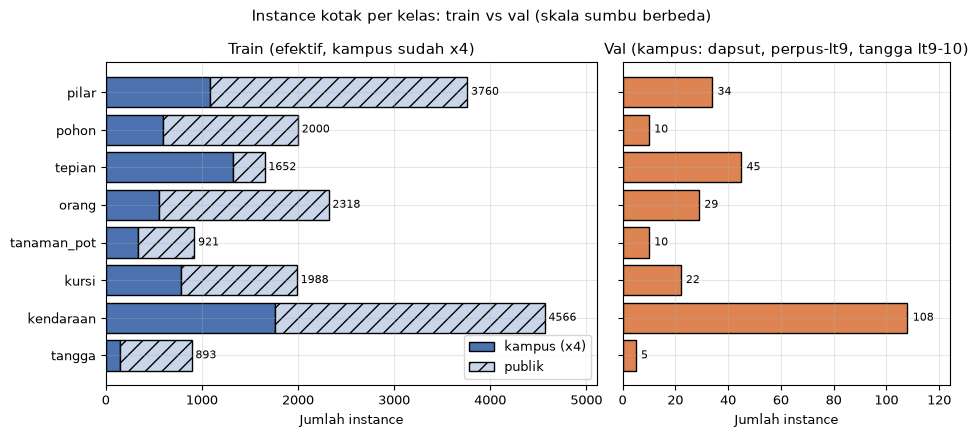

Rasio kelas terbesar : terkecil di train efektif = 5.1x (kendaraan vs tangga); di val = 22x (kendaraan vs tangga).


In [9]:
# --- diagram: instance per kelas, train vs val -------------------------------------------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.7, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
y = np.arange(8)
a1.barh(y, v_k4, color="#4c72b0", edgecolor="k", label=f"kampus (x{FAK})")
a1.barh(y, v_pub, left=v_k4, color="#c9d6ea", edgecolor="k", hatch="//", label="publik")
for i in range(8):
    a1.text(v_train[i] + 40, i, str(v_train[i]), va="center", fontsize=8)
a1.set_yticks(y); a1.set_yticklabels(NAMA_KOTAK); a1.invert_yaxis()
a1.set_xlabel("Jumlah instance"); a1.set_title(f"Train (efektif, kampus sudah x{FAK})"); a1.legend(loc="lower right")
a1.set_xlim(0, max(v_train) * 1.12)
a2.barh(y, v_val, color="#dd8452", edgecolor="k")
for i in range(8):
    a2.text(v_val[i] + 2, i, str(v_val[i]), va="center", fontsize=8)
a2.set_yticks(y); a2.set_yticklabels([]); a2.invert_yaxis()
a2.set_xlabel("Jumlah instance"); a2.set_title("Val (kampus: dapsut, perpus-lt9, tangga lt9-10)")
a2.set_xlim(0, max(v_val) * 1.15)
fig.suptitle("Instance kotak per kelas: train vs val (skala sumbu berbeda)")
fig.tight_layout(); plt.show()
rasio = max(v_train) / min(v_train)
print(f"Rasio kelas terbesar : terkecil di train efektif = {rasio:.1f}x ({NAMA_KOTAK[v_train.index(max(v_train))]} vs {NAMA_KOTAK[v_train.index(min(v_train))]}); "
      f"di val = {max(v_val)/min(v_val):.0f}x ({NAMA_KOTAK[v_val.index(max(v_val))]} vs {NAMA_KOTAK[v_val.index(min(v_val))]}).")

In [10]:
# --- segmentasi v4 (kampus saja, tanpa pengulangan) -----------------------------------------------------
seg = {sp: hitung_label(DATA / f"dataset-gabung-seg-v4/labels/{sp}", 3)["all"] for sp in ("train", "val")}
baris = [[NAMA_SEG[i], seg["train"][i], seg["val"][i]] for i in range(3)]
baris.append(["total", sum(seg["train"].values()), sum(seg["val"].values())])
tabel(["Kelas (segmentasi)", "Train", "Val"], baris, rata_kanan=[1, 2])

# --- test set: frame dan kotak per lokasi (hanya membaca label; frame test tidak ditampilkan) ----------
lok_test = {r["filename"]: r["lokasi"] for r in test_daftar}
kt = collections.defaultdict(collections.Counter); fr_t = collections.Counter(); seg_t = collections.defaultdict(collections.Counter)
for f in sorted((DATA / "dataset-test-kotak/labels/test").glob("*.txt")):
    lok = lok_test[f.stem + ".jpg"]; fr_t[lok] += 1
    for ln in f.read_text().splitlines():
        if ln.strip(): kt[lok][int(ln.split()[0])] += 1
for f in sorted((DATA / "dataset-test-seg/labels/test").glob("*.txt")):
    lok = lok_test[f.stem + ".jpg"]
    for ln in f.read_text().splitlines():
        if ln.strip(): seg_t[lok][int(ln.split()[0])] += 1
baris = []
for lok in sorted(fr_t):
    baris.append([lok, fr_t[lok], sum(kt[lok].values())] + [kt[lok][i] for i in range(8)] + [seg_t[lok][0], seg_t[lok][1], seg_t[lok][2]])
tot_kt = [sum(kt[l][i] for l in kt) for i in range(8)]
baris.append(["total", sum(fr_t.values()), sum(tot_kt)] + tot_kt + [sum(seg_t[l][i] for l in seg_t) for i in range(3)])
tabel(["Lokasi test", "Frame", "Kotak"] + NAMA_KOTAK + ["seg: jalur_jalan", "seg: jalan_kend.", "seg: tangga"], baris, rata_kanan=list(range(1, 14)))

Kelas (segmentasi),Train,Val
jalur_jalan,373,33
jalan_kendaraan,123,23
tangga,44,11
total,540,67


Lokasi test,Frame,Kotak,pilar,pohon,tepian,orang,tanaman_pot,kursi,kendaraan,tangga,seg: jalur_jalan,seg: jalan_kend.,seg: tangga
pot-lt11-ubm-tower,23,64,1,0,30,5,28,0,0,0,26,0,0
selasar-lt11-ubm-tower,22,20,6,0,0,14,0,0,0,0,21,0,0
taman-ubm,46,153,31,3,21,13,71,14,0,0,49,16,0
total,91,237,38,3,51,32,99,14,0,0,96,16,0


**Bacaan.** Ada ketimpangan kelas: kendaraan dan pilar paling banyak di train (sebagian besarnya dari dataset publik),
sedangkan tangga dan tanaman_pot paling sedikit; rasionya dicetak di bawah grafik. Ketimpangan di val jauh lebih tajam,
dan kelas kecil (pohon, tanaman_pot, tangga) hanya punya sedikit instance, jadi mAP per kelas untuk kelas itu berisik.
Di test, **kendaraan dan tangga bernilai nol** dan kursi hanya ada di satu lokasi; test set ini tidak dapat menilai
kelas tersebut. Segmentasi memiliki jauh lebih sedikit data (kampus saja), dengan `jalan_kendaraan` dan `tangga` jauh di
bawah `jalur_jalan`.

## 6. Ringkasan audit label
Setelah baseline pertama, tim menemukan label kampus yang tidak konsisten (sirip dinding kaca dilabel pilar, orang di
balik kaca, pot kecil di rak, kotak terlalu kecil, kotak ganda). Label diperiksa terhadap aturan **R1–R7**
(`docs/kelas.md`); jumlah kotak yang dihapus dihitung di sel di bawah dari `docs/hasil-audit.md`.
Catatan penting: audit dilakukan pada label **pilot** (frame train dan val awal); frame dari ronde 2 dan ronde 4
dilabel kemudian dengan aturan yang sudah termasuk R1–R7.

Aturan,Isi singkat
R1,"Sirip, mullion, kosen, kusen pintu, bagian dinding/fasad/balustrade bukan pilar, bahan apa pun. Kolom bebas tetap pilar."
R2,"Orang di balik kaca (ruang yang tidak bisa dimasuki) tidak dilabel. Kalau ragu, tetap orang."
R3,Pot kecil di rak tidak dilabel.
R4,Ambang ukuran (1080x1920): kelas biasa sisi terpendek >= 96 px; pilar/pohon/tepian sisi terpanjang >= 96 px dan terpendek >= 24 px.
R5,"Tanpa pantulan, mural, poster, patung; eskalator tidak dilabel."
R6,Satu objek satu kotak: kotak ganda atau parsial dihapus.
R7,"Di luar kelas: gerbang putar, badan portal, kaki meja, lampu langit-langit, kabinet listrik, penyangga pohon."


Dari tabel: total dihapus val 66 + train 89 = 155. Dijumlah ulang dari baris: val 66, train 89, semua 155.
Aturan dengan penghapusan terbanyak: R4 (75 dari 155 kotak, 48%).


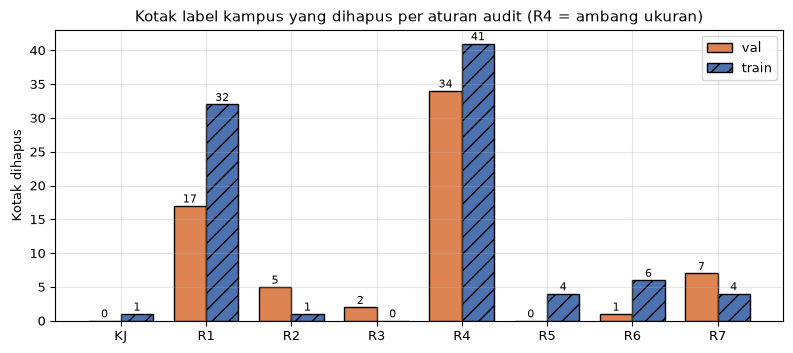

In [11]:
au = baca(ROOT / "docs/hasil-audit.md")
# --- aturan R1-R7 -----------------------------------------------------------------------------------
aturan = tabel_md(au, "| Aturan | Isi singkat |")
tabel(["Aturan", "Isi singkat"], aturan)

# --- kotak yang dihapus per aturan (bagian 4.1) --------------------------------------------------------
hapus = tabel_md(au, "| Aturan | val | train | Total |")
def jumlah_sel(s):
    # "kendaraan 2, kursi 14, orang 18" -> 34 ; "-" -> 0
    return sum(int(x) for x in re.findall(r"\s(\d+)", " " + s.replace("**", ""))) if s.strip() not in ("-", "") else 0
nama_aturan, v_h, t_h = [], [], []
for r in hapus:
    if r[0].replace("*", "") == "Total":
        tot_val, tot_train, tot_all = angka_md(r[1]), angka_md(r[2]), angka_md(r[3])
    else:
        nama_aturan.append(r[0]); v_h.append(jumlah_sel(r[1])); t_h.append(jumlah_sel(r[2]))
print(f"Dari tabel: total dihapus val {tot_val} + train {tot_train} = {tot_all}. Dijumlah ulang dari baris: val {sum(v_h)}, train {sum(t_h)}, semua {sum(v_h)+sum(t_h)}.")
tot_rule = {n: a + b for n, a, b in zip(nama_aturan, v_h, t_h)}
atas = max(tot_rule, key=tot_rule.get)
print(f"Aturan dengan penghapusan terbanyak: {atas} ({tot_rule[atas]} dari {sum(tot_rule.values())} kotak, {100*tot_rule[atas]/sum(tot_rule.values()):.0f}%).")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(nama_aturan)); w = 0.38
b1 = ax.bar(x - w/2, v_h, w, color="#dd8452", edgecolor="k", label="val")
b2 = ax.bar(x + w/2, t_h, w, color="#4c72b0", edgecolor="k", hatch="//", label="train")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, int(b.get_height()), ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(nama_aturan); ax.set_ylabel("Kotak dihapus"); ax.legend()
ax.set_title("Kotak label kampus yang dihapus per aturan audit (R4 = ambang ukuran)")
fig.tight_layout(); plt.show()

Kelas,Val sebelum (v1),Val sesudah (v2),Train kampus sebelum,Train kampus sesudah
pilar,50,34,151,112
pohon,10,10,82,79
tepian,45,45,168,157
orang,52,29,93,79
tanaman_pot,13,10,47,44
kursi,36,22,155,152
kendaraan,108,108,271,255
tangga,5,5,20,20
total,319,263,987,898


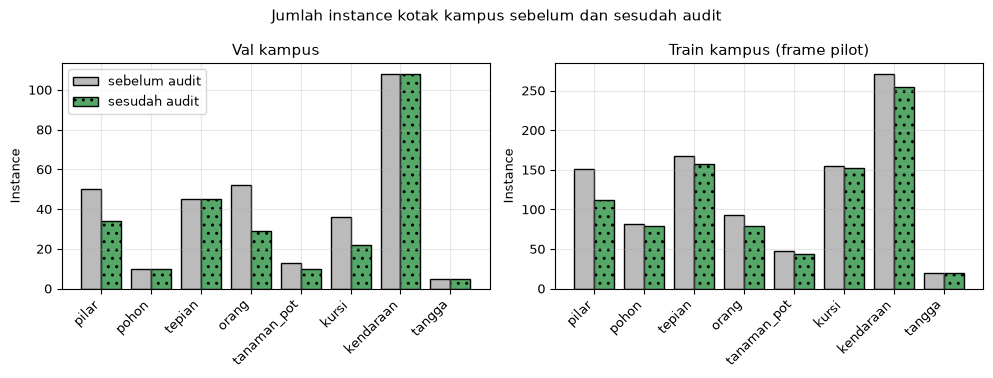

Val sesudah audit (hasil-audit.md): 263 | val di dataset v4 (dihitung dari label): 263 -> konsisten


In [12]:
# --- sebelum / sesudah per kelas (bagian 4.2): val dan train kampus -----------------------------------------
def tab_sesudah(penanda):
    t = tabel_md_setelah(au, penanda, "| Kelas | v1 | v2-noR4 | v2 |")
    return [(r[0].replace("*", ""), angka_md(r[1]), angka_md(r[3])) for r in t]
tv, tt = tab_sesudah("**Val**"), tab_sesudah("**Train kampus**")
baris = []
for (k, a, b), (_, c, d) in zip(tv, tt):
    baris.append([k, a, b, c, d])
tabel(["Kelas", "Val sebelum (v1)", "Val sesudah (v2)", "Train kampus sebelum", "Train kampus sesudah"], baris, rata_kanan=[1, 2, 3, 4])

kls = [k for k, _, _ in tv if k != "total"]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for ax, tb, judul in ((axs[0], tv, "Val kampus"), (axs[1], tt, "Train kampus (frame pilot)")):
    dd = {k: (a, b) for k, a, b in tb}
    x = np.arange(len(kls)); w = 0.4
    ax.bar(x - w/2, [dd[k][0] for k in kls], w, color="#bbbbbb", edgecolor="k", label="sebelum audit")
    ax.bar(x + w/2, [dd[k][1] for k in kls], w, color="#55a868", edgecolor="k", hatch="..", label="sesudah audit")
    ax.set_xticks(x); ax.set_xticklabels(kls, rotation=45, ha="right"); ax.set_title(judul); ax.set_ylabel("Instance")
axs[0].legend()
fig.suptitle("Jumlah instance kotak kampus sebelum dan sesudah audit"); fig.tight_layout(); plt.show()

# cek konsistensi dengan dataset v4 (val tidak berubah sejak audit)
tot_v2_val = dict((k, b) for k, a, b in tv)["total"]
print(f"Val sesudah audit (hasil-audit.md): {tot_v2_val} | val di dataset v4 (dihitung dari label): {sum(v_val)} -> {'konsisten' if tot_v2_val == sum(v_val) else 'BERBEDA'}")

**Bacaan.** Audit mengubah **cara menilai**, bukan modelnya. Aturan dengan penghapusan terbanyak dicetak di bawah grafik
(R4 = benda kecil di bawah ambang ukuran), dan menurut `hasil-audit.md` bagian 6 kenaikan skor val setelah audit terutama
berasal dari koreksi label, bukan model yang lebih pandai. Angka val sesudah audit sama dengan val pada dataset v4, jadi val tetap
sama di semua ronde berikutnya. Train kampus v4 lebih besar daripada frame pilot yang diaudit karena ronde 2 dan ronde 4
menambah frame baru.

## 7. Contoh gambar
Dua baris pertama: enam frame kampus dari **data latih** v4 (sudah diburamkan wajahnya) dengan kotak labelnya.
Baris ketiga: gambar dari dataset publik. Gambar hanya diambil dari `data/dataset-gabung-kotak-v4/images/` dan
diperkecil sehingga lebar keseluruhan tidak lebih dari 1000 px. Frame test tidak ditampilkan.

Baris 1-2: frame kampus (train): parkiran-motor-b1-ubm-tower_2026-10-30_01_mata_t0064003, lorong-lt9-ubm-tower_2026-10-30_03_mata_t0008024, jalanan-ubm_2026-11-07_01_dada_t0107017, samping-ubm_2026-11-07_01_mata_t0090016, lab1-lt5-alfa-tower_2026-10-30_02_mata_t0000000, tangga-naik-lt3-alfa-tower_2026-10-30_01_mata_t0021007
Ukuran asli frame kampus (lebar x tinggi, px): (1080, 1920)


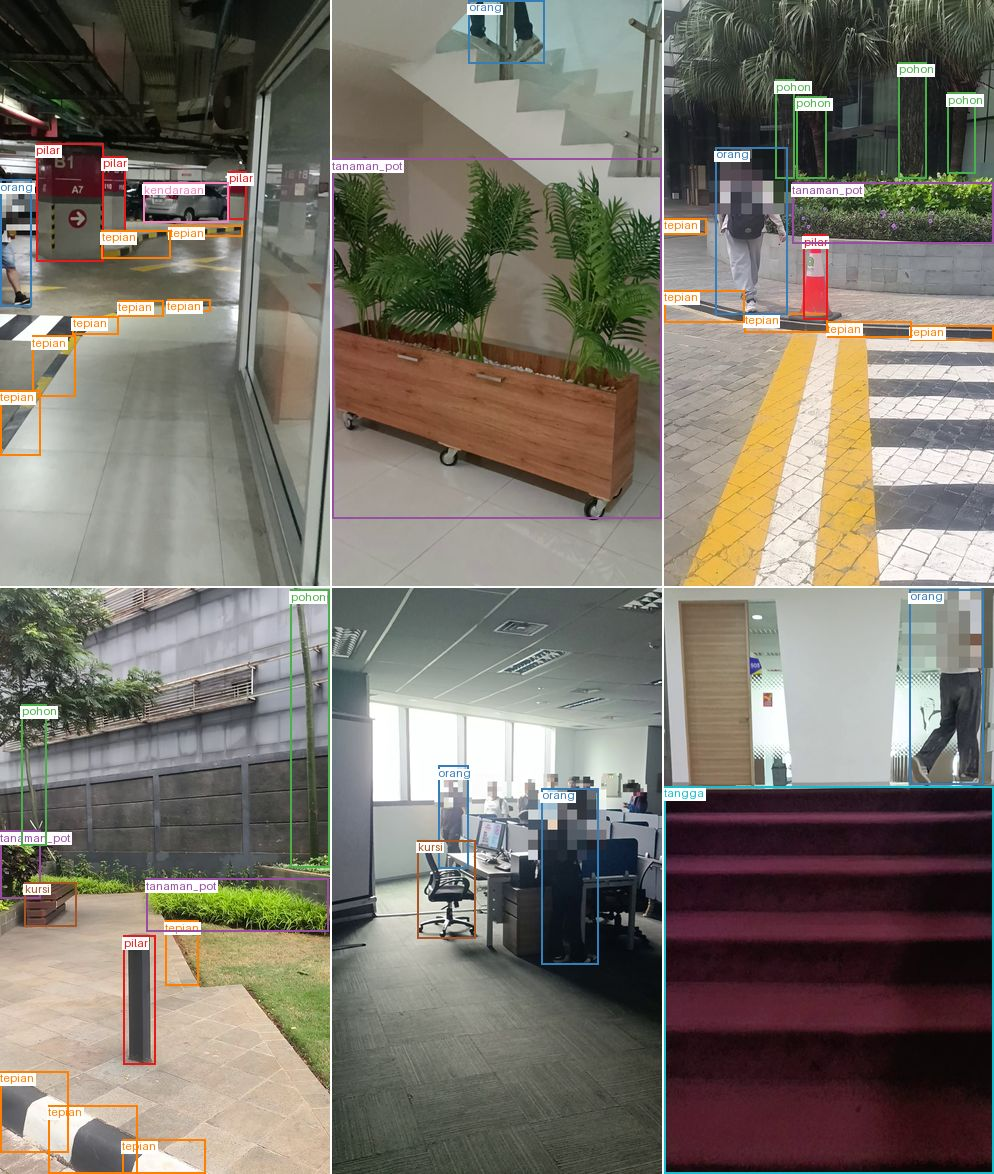

In [13]:
FONT = ImageFont.load_default(size=11)
def gambar_dgn_kotak(path, lebar):
    img = Image.open(path).convert("RGB")
    W, H = img.size
    sk = lebar / W
    img = img.resize((lebar, int(H * sk)), Image.LANCZOS)
    d = ImageDraw.Draw(img)
    lab = (path.parents[2] / "labels" / path.parent.name / (path.stem + ".txt"))
    warna = ["#e41a1c", "#4daf4a", "#ff7f00", "#377eb8", "#984ea3", "#a65628", "#f781bf", "#17becf"]
    for ln in lab.read_text().splitlines():
        if not ln.strip():
            continue
        p = ln.split(); c = int(p[0]); xc, yc, w, h = map(float, p[1:5])
        x1, y1, x2, y2 = (xc - w/2) * lebar, (yc - h/2) * img.size[1], (xc + w/2) * lebar, (yc + h/2) * img.size[1]
        d.rectangle([x1, y1, x2, y2], outline=warna[c], width=2)
        teks = NAMA_KOTAK[c]
        tb = d.textbbox((x1, y1), teks, font=FONT)
        d.rectangle([tb[0]-1, tb[1]-1, tb[2]+1, tb[3]+1], fill="white")
        d.text((x1, y1), teks, fill=warna[c], font=FONT)
    return img

IMG_DIR = DATA / "dataset-gabung-kotak-v4/images/train"
LAB_DIR = DATA / "dataset-gabung-kotak-v4/labels/train"
# pilih 6 lokasi berbeda; di tiap lokasi ambil frame unik dengan kelas paling beragam (deterministik)
LOK_CONTOH = ["parkiran-motor-b1-ubm-tower", "lorong-lt9-ubm-tower", "jalanan-ubm", "samping-ubm", "lab1-lt5-alfa-tower", "tangga-naik-lt3-alfa-tower"]
pilih = []
for lok in LOK_CONTOH:
    best = None
    for r in uniq:
        if r["split"] == "train" and r["image"].startswith(lok + "_"):
            kl = {int(x.split()[0]) for x in (LAB_DIR / (Path(r["image"]).stem + ".txt")).read_text().splitlines() if x.strip()}
            kunci = (len(kl), r["image"])
            if best is None or kunci > best[0]:
                best = (kunci, r["image"])
    pilih.append(best[1])

LEBAR = 330
gambars = []
for nm in pilih:
    p = IMG_DIR / nm; cek_putih(p); gambars.append(gambar_dgn_kotak(p, LEBAR))
tinggi = max(g.size[1] for g in gambars)
kanvas = Image.new("RGB", (3 * LEBAR + 4, 2 * tinggi + 2), "white")
for i, g in enumerate(gambars):
    kanvas.paste(g, ((i % 3) * (LEBAR + 2), (i // 3) * (tinggi + 2)))
print("Baris 1-2: frame kampus (train):", ", ".join(Path(n).stem for n in pilih))
print("Ukuran asli frame kampus (lebar x tinggi, px):", Image.open(IMG_DIR / pilih[0]).size)
tampil_jpeg(kanvas)

Publik (kiri ke kanan), ukuran asli: trotoar (640, 640), unstructured (360, 640), ood (640, 480), rod (640, 640)


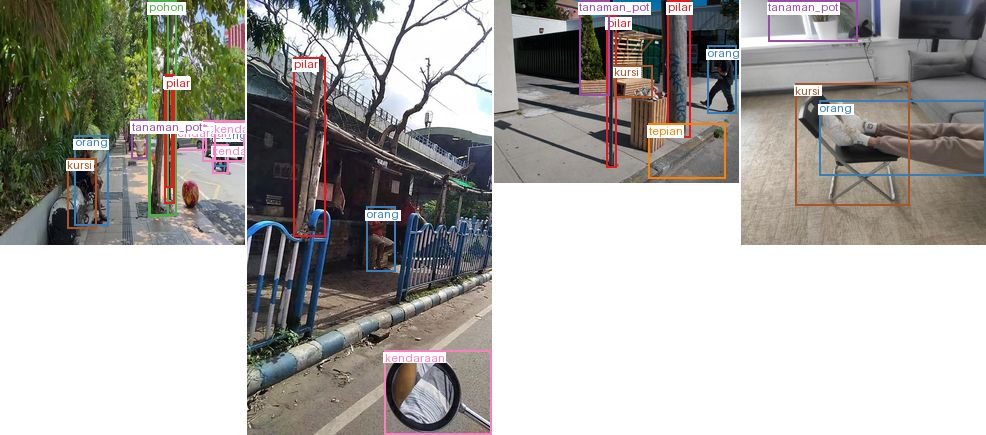

In [14]:
# baris publik: satu gambar per dataset publik (yang punya kelas paling beragam)
pub_pilih = []
for s in ("trotoar", "unstructured", "ood", "rod"):
    best = None
    for r in sumber_csv:
        if r["split"] == "train" and r["sumber"] == s:
            kl = {int(x.split()[0]) for x in (LAB_DIR / (Path(r["image"]).stem + ".txt")).read_text().splitlines() if x.strip()}
            kunci = (len(kl), r["image"])
            if best is None or kunci > best[0]:
                best = (kunci, r["image"])
    pub_pilih.append((s, best[1]))
L2 = 245
gp = []
for s, nm in pub_pilih:
    p = IMG_DIR / nm; cek_putih(p); gp.append(gambar_dgn_kotak(p, L2))
th = max(g.size[1] for g in gp)
kv = Image.new("RGB", (4 * L2 + 6, th), "white")
for i, g in enumerate(gp):
    kv.paste(g, (i * (L2 + 2), 0))
print("Publik (kiri ke kanan), ukuran asli:", ", ".join(f"{s} {Image.open(IMG_DIR / nm).size}" for s, nm in pub_pilih))
tampil_jpeg(kv)

**Bacaan.** Frame kampus beresolusi tinggi dan portrait (ukurannya dicetak di atas gambar), objek sering tipis dan panjang (pilar, tepian),
sedangkan gambar publik jauh lebih kecil dengan gaya foto yang berbeda (sudut pandang, pencahayaan, jenis objek).
Kotak yang tampak "terlewat" di sini adalah akibat aturan label (misalnya batas ukuran R4), bukan kesalahan menggambar.

## 8. Keterbatasan
Angka di bawah dihitung dari berkas yang sama dengan bagian sebelumnya.

In [15]:
boc = baca_csv(DATA / "ronde2/bocor/dikeluarkan.csv") if (DATA / "ronde2/bocor/dikeluarkan.csv").exists() else []
boc_asal = dict(collections.Counter(r["asal"] for r in boc))
n_nontest = TOT_NONTEST
pers_lab = 100 * N_LAB_TRAIN / n_nontest
kls_nol_test = [NAMA_KOTAK[i] for i in range(8) if tot_kt[i] == 0]
val_kecil = [(NAMA_KOTAK[i], v_val[i]) for i in range(8) if v_val[i] < 20]
tabel(["Keterbatasan", "Angka (dihitung)"], [
    ["Frame kampus berlabel dibanding frame tersedia (non-test)", f"{N_LAB_TRAIN} frame train + {N_LAB_VAL} val dari {n_nontest} frame non-test ({pers_lab:.1f}% untuk train)"],
    ["Ketimpangan kelas di train efektif", f"terbesar {max(v_train)} vs terkecil {min(v_train)} instance ({rasio:.1f}x)"],
    ["Kelas dengan < 20 instance di val (mAP per kelas berisik)", ", ".join(f"{k} ({n})" for k, n in val_kecil)],
    ["Kelas dengan 0 instance di test (tidak dapat dinilai)", ", ".join(kls_nol_test) + " (seg: tangga juga 0)"],
    ["Ukuran test set", f"{sum(fr_t.values())} frame, {sum(tot_kt)} kotak, hanya {len(fr_t)} lokasi"],
    ["Ukuran val set", f"{N_LAB_VAL} frame, {sum(v_val)} instance, {sum(1 for l in split_lok if split_lok[l] == 'val')} lokasi"],
    ["Porsi pseudo-label COCO di kotak publik", f"{100*tot_c/(tot_a+tot_c):.0f}% dari kotak publik"],
    ["Segmentasi tanpa data publik", f"{sum(seg['train'].values())} polygon train, {sum(seg['val'].values())} polygon val (kampus saja)"],
    ["Frame dikeluarkan karena kebocoran lokasi taman-ubm", f"{len(boc)} frame ({boc_asal})"],
    [f"Kampus x{FAK} tidak menambah informasi baru", f"{tr_unik} frame unik menjadi {tr_total} gambar di train"],
], )

Keterbatasan,Angka (dihitung)
Frame kampus berlabel dibanding frame tersedia (non-test),391 frame train + 54 val dari 3790 frame non-test (10.3% untuk train)
Ketimpangan kelas di train efektif,terbesar 4566 vs terkecil 893 instance (5.1x)
Kelas dengan < 20 instance di val (mAP per kelas berisik),"pohon (10), tanaman_pot (10), tangga (5)"
Kelas dengan 0 instance di test (tidak dapat dinilai),"kendaraan, tangga (seg: tangga juga 0)"
Ukuran test set,"91 frame, 237 kotak, hanya 3 lokasi"
Ukuran val set,"54 frame, 263 instance, 3 lokasi"
Porsi pseudo-label COCO di kotak publik,15% dari kotak publik
Segmentasi tanpa data publik,"540 polygon train, 67 polygon val (kampus saja)"
Frame dikeluarkan karena kebocoran lokasi taman-ubm,"16 frame ({'train-v2': 12, 'ronde2': 4})"
Kampus x4 tidak menambah informasi baru,391 frame unik menjadi 1564 gambar di train


- **Sedikit frame kampus yang berlabel.** Label manual mahal sehingga hanya sebagian kecil frame yang dilabel; model lebih
  banyak belajar dari gambar publik (yang gayanya berbeda) daripada dari kondisi pemakaian nyata.
- **Ketimpangan kelas.** Kelas sedikit (tangga, tanaman_pot, pohon) mudah terlewat dan nilainya di val berisik.
- **Val dan test kecil.** Val hanya 54 frame dari tiga lokasi; test 91 frame dari tiga lokasi. Satu hari rekaman per
  lokasi: cuaca dan pencahayaan terbatas.
- **Test tidak mencakup kendaraan dan tangga.** Kinerja kedua kelas hanya bisa dibaca dari val, bukan test.
- **Kebocoran lokasi taman-ubm.** Frame test sendiri tidak masuk data latih, tetapi tempat yang sama terekam di video lokasi
  lain. Setelah ditemukan, **16 frame dikeluarkan**: **12 frame latih lama** (8 tangga-naik-alfa-lt2, 4 jalanan-ubm) dan **4 frame kandidat ronde 2**
  yang dibuang saat review (1 lorong-lt3, 3 jalanan-ubm); 12 + 4 = 16 cocok dengan tabel di atas. Baseline lama **dilatih dengan 12 frame itu**: karena
  frame kampus di-*oversample* x4, ada **48 dari 3.080 gambar latih model kotak** (1,6%) yang berasal dari frame bocor, dan 12 dari 195 frame latih model
  segmentasi. Baseline tidak dilatih ulang, jadi angkanya di taman-ubm kemungkinan sedikit terlalu optimis; model ronde 2 dilatih tanpa frame itu
  (angka dari `docs/test-set.md` dan `docs/hasil-ronde2.md`, bukan hasil hitung sel). Kemiripan visual yang tersisa mungkin masih ada.
- **Label draf otomatis memengaruhi gaya label.** Walau semua frame ditinjau manusia, bentuk polygon draf (SAM) dan sumber
  draf berbeda per ronde dapat membuat gaya label tidak seragam antar ronde.
- **Aturan label berubah selama proyek** (riwayat versi di `docs/kelas.md`, ID kelas tetap). Audit R1–R7 hanya dijalankan pada label pilot;
  label ronde 2 dan 4 dibuat setelahnya dengan aturan yang sudah termasuk R1–R7.
- **Privasi.** Hanya frame yang diburamkan yang disimpan. Pemburaman otomatis bisa melewatkan kepala yang tidak terdeteksi;
  karena itu seluruh `data/` tidak masuk Git.

## 9. Pemeriksaan angka acuan
Tabel ini membandingkan angka hitungan notebook dengan angka yang tercatat di dokumen proyek. Angka hanya dilaporkan
sesuai hasil hitung; tidak ada yang disesuaikan agar cocok.

In [16]:
cek = [
    ("Gambar train kotak v4", 3864, tr_total + n_pub),
    ("Gambar val kotak v4", 54, img_cnt[("val", "campus")]),
    ("File gambar train kotak v4 (hitung folder)", 3864, len(list((DATA / "dataset-gabung-kotak-v4/images/train").glob("*.jpg")))),
    ("File gambar val kotak v4 (hitung folder)", 54, len(list((DATA / "dataset-gabung-kotak-v4/images/val").glob("*.jpg")))),
    ("Frame val (kampus)", 54, N_LAB_VAL),
    ("Frame test", 91, sum(fr_t.values())),
    ("Kotak test", 237, sum(tot_kt)),
    ("Frame kampus berlabel (train, unik)", 391, N_LAB_TRAIN),
    ("Frame non-test (diekstrak, diburamkan)", 3790, TOT_NONTEST),
    ("Gambar publik di train (sekitar 2300)", 2300, n_pub),
]
baris = [[n, e, h, "OK" if e == h else "BEDA"] for n, e, h in cek]
tabel(["Angka acuan", "Diharapkan", "Dihitung", "Status"], baris, rata_kanan=[1, 2])
print("Catatan: frame kampus berlabel total (train unik + val) =", N_LAB_TRAIN + N_LAB_VAL)
print()
print("Gambar yang ditampilkan di notebook ini:")
for g in GAMBAR_TAMPIL:
    print(" -", g)

Angka acuan,Diharapkan,Dihitung,Status
Gambar train kotak v4,3864,3864,OK
Gambar val kotak v4,54,54,OK
File gambar train kotak v4 (hitung folder),3864,3864,OK
File gambar val kotak v4 (hitung folder),54,54,OK
Frame val (kampus),54,54,OK
Frame test,91,91,OK
Kotak test,237,237,OK
"Frame kampus berlabel (train, unik)",391,391,OK
"Frame non-test (diekstrak, diburamkan)",3790,3790,OK
Gambar publik di train (sekitar 2300),2300,2300,OK


Catatan: frame kampus berlabel total (train unik + val) = 445

Gambar yang ditampilkan di notebook ini:
 - data/dataset-gabung-kotak-v4/images/train/parkiran-motor-b1-ubm-tower_2026-10-30_01_mata_t0064003.jpg
 - data/dataset-gabung-kotak-v4/images/train/lorong-lt9-ubm-tower_2026-10-30_03_mata_t0008024.jpg
 - data/dataset-gabung-kotak-v4/images/train/jalanan-ubm_2026-11-07_01_dada_t0107017.jpg
 - data/dataset-gabung-kotak-v4/images/train/samping-ubm_2026-11-07_01_mata_t0090016.jpg
 - data/dataset-gabung-kotak-v4/images/train/lab1-lt5-alfa-tower_2026-10-30_02_mata_t0000000.jpg
 - data/dataset-gabung-kotak-v4/images/train/tangga-naik-lt3-alfa-tower_2026-10-30_01_mata_t0021007.jpg
 - data/dataset-gabung-kotak-v4/images/train/trotoar_O1087_jpg.rf.9f67f9dc4434931219c8fe693ede45f4.jpg
 - data/dataset-gabung-kotak-v4/images/train/unstructured_VID_20230719_080342_mp4-18_jpg.rf.c62aa89a91ac2e75675a1686bd762d4e.jpg
 - data/dataset-gabung-kotak-v4/images/train/ood_3bd98bd606bae83d_jpg.rf.8ceebb5b9